# Extended-sample study (main evidence): does the result hold over 2000-2026?

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import roc_auc_score, brier_score_loss, adjusted_rand_score
from xgboost import XGBClassifier
from scipy.stats import norm, skew, kurtosis

SEED, COST_BPS, W_CORE, W_SAT, BAND = 42, 5, 0.5, 0.5, 0.10
END_DATE = "2026-10-01"
SNAP, OUT = "data/snapshot_long", "results/extended"
os.makedirs(f"{OUT}/figures", exist_ok=True)

close = pd.read_csv(f"{SNAP}/close.csv", index_col=0, parse_dates=True)
volume = pd.read_csv(f"{SNAP}/volume.csv", index_col=0, parse_dates=True)
macro = pd.read_csv(f"{SNAP}/macro.csv", index_col=0, parse_dates=True)
SECTORS = ["XLB", "XLE", "XLF", "XLI", "XLK", "XLP", "XLU", "XLV", "XLY"]
NON_STOCKS = set(SECTORS + ["SPY", "TLT", "GLD", "IEF", "SHY", "BIL"])
STOCKS = [t for t in close.columns if t not in NON_STOCKS and close[t].notna().any()]
print(f"{close.shape[1]} tickers, {close.index.min().date()} to {close.index.max().date()}; {len(STOCKS)} stocks with data")

114 tickers, 1993-01-04 to 2026-09-30; 98 stocks with data


## 1 Weekly features (same definitions as the main notebook)

In [3]:
spy_close = close["SPY"].dropna()
daily_ret = np.log(spy_close).diff()
weekly = pd.DataFrame({"close": spy_close.resample("W-FRI").last(),
                       "volume": volume["SPY"].reindex(spy_close.index).resample("W-FRI").sum()})
weekly["ret_1w"] = np.log(weekly["close"]).diff()
weekly["ret_4w"] = np.log(weekly["close"]).diff(4)
weekly["ret_13w"] = np.log(weekly["close"]).diff(13)
weekly["rvol_1w"] = daily_ret.resample("W-FRI").std() * np.sqrt(252)
weekly["rvol_13w"] = weekly["ret_1w"].rolling(13).std() * np.sqrt(52)
weekly["dist_ma40w"] = np.log(weekly["close"] / weekly["close"].rolling(40).mean())
weekly["drawdown_52w"] = weekly["close"] / weekly["close"].rolling(52).max() - 1
weekly["volume_ratio"] = weekly["volume"] / weekly["volume"].rolling(13).mean()
REGIME_FEATURES = ["ret_1w", "ret_4w", "ret_13w", "rvol_1w", "rvol_13w", "dist_ma40w", "drawdown_52w", "volume_ratio"]
RETURN_FEATURES = ["ret_1w", "ret_4w", "ret_13w", "dist_ma40w", "drawdown_52w"]     # no volatility, no volume
features = weekly.loc[:END_DATE, REGIME_FEATURES].dropna()
X = features
STATE_COLS = REGIME_FEATURES + ["regime_now", "stress_4w"]
print(f"Features: {len(X)} weeks, {X.index.min().date()} to {X.index.max().date()}")

rf_w = ((1 + macro["tbill_3m"].ffill() / 100) ** (1 / 52) - 1).resample("W-FRI").last().ffill()
def excess(ret):
    """Weekly return minus the 3-month T-bill rate for the same week."""
    return ret - rf_w.reindex(ret.index).fillna(0)

Features: 1705 weeks, 1994-01-21 to 2026-09-25


## 2 Rule-based sleeves

Each January the aggressive sleeve is re-selected from betas to SPY over the previous three years of daily returns
(at least two years of data required), equal-weighted and rebalanced daily. The defensive sleeve is TLT + GLD
(available from November 2004) or 3-month T-bills.

In [4]:
ret_d = close.pct_change(fill_method=None)
spy_d = ret_d["SPY"]
def weekly_ret(x):
    """Compound daily simple returns into Friday-to-Friday weekly returns."""
    return ((1 + x).resample("W-FRI").prod(min_count=1) - 1).loc[:END_DATE]

def select_basket(universe, n, y, lookback=756, min_obs=504):
    """Top-n names by beta to SPY over the 3 years before January of year y (at least 2 years of data)."""
    hist = ret_d.loc[:f"{y-1}-12-31", universe].iloc[-lookback:]
    ok = [t for t in universe if hist[t].count() >= min_obs]
    s = spy_d.reindex(hist.index)
    beta = pd.Series({t: hist[t].cov(s) / s[hist[t].notna()].var() for t in ok})
    return list(beta.sort_values(ascending=False).index[:n])

def basket_next(top):
    """Next-week return of an equal-weighted basket (signal at Friday t earns week t+1)."""
    return weekly_ret(ret_d[top].mean(axis=1)).shift(-1)

core_next = weekly_ret(spy_d).shift(-1)
tltgld_next = weekly_ret(ret_d[["TLT", "GLD"]].mean(axis=1, skipna=False)).shift(-1)
cash_next = rf_w.reindex(core_next.index).shift(-1)

SETUPS = {"A: sector ETFs / TLT+GLD": dict(universe=SECTORS, n=4, defensive=tltgld_next, years=range(2006, 2027)),
          "B: S&P 100 stocks / TLT+GLD": dict(universe=STOCKS, n=10, defensive=tltgld_next, years=range(2006, 2027)),
          "C: sector ETFs / T-bills": dict(universe=SECTORS, n=4, defensive=cash_next, years=range(2001, 2027))}
for name, cfg in SETUPS.items():
    cfg["baskets"] = {y: select_basket(cfg["universe"], cfg["n"], y) for y in cfg["years"]}
    cfg["agg_next"] = {y: basket_next(cfg["baskets"][y]) for y in cfg["years"]}
    agg = pd.Series(np.nan, index=core_next.index)
    for y in cfg["years"]:
        yi = agg.index[(agg.index >= f"{y}-01-01") & (agg.index < f"{y+1}-01-01")]
        agg.loc[yi] = cfg["agg_next"][y].reindex(yi).values
    cfg["r"] = pd.DataFrame({"Core (SPY)": core_next, "Aggressive sleeve": agg, "Defensive sleeve": cfg["defensive"]})
    picks = pd.Series({y: ", ".join(cfg["baskets"][y]) for y in cfg["years"]})
    print(f"\n{name}: baskets in selected years")
    print(picks.iloc[::5].to_string())


A: sector ETFs / TLT+GLD: baskets in selected years
2006    XLK, XLY, XLB, XLF
2011    XLF, XLE, XLB, XLY
2016    XLE, XLF, XLB, XLI
2021    XLE, XLK, XLF, XLI
2026    XLK, XLY, XLI, XLF



B: S&P 100 stocks / TLT+GLD: baskets in selected years
2006    NVDA, SCHW, AMD, BKNG, TXN, NFLX, INTC, MS, AM...
2011        MS, BAC, C, AIG, COF, MET, WFC, SPG, JPM, AXP
2016    SCHW, NOW, MS, AVGO, BLK, MET, TSLA, C, CRM, AMGN
2021        BA, NVDA, COF, C, AMD, MS, AXP, COP, MET, AIG
2026    TSLA, NVDA, AMD, AVGO, INTC, QCOM, META, AMZN,...



C: sector ETFs / T-bills: baskets in selected years
2001    XLK, XLF, XLY, XLV
2006    XLK, XLY, XLB, XLF
2011    XLF, XLE, XLB, XLY
2016    XLE, XLF, XLB, XLI
2021    XLE, XLK, XLF, XLI
2026    XLK, XLY, XLI, XLF


## 3 Causal labellers and walk-forward forecasts (2000-2026)

Every January the labeller is refit on all earlier weeks (from 1994), the labels, `regime_now`, `stress_4w` and the
next-week target are rebuilt from it, and XGBoost (same settings as the main study) forecasts the coming year.

In [5]:
class AutoEncoder(nn.Module):
    def __init__(self, n_in, n_hidden=6, n_latent=3):
        super().__init__()
        self.enc = nn.Sequential(nn.Linear(n_in, n_hidden), nn.ReLU(), nn.Linear(n_hidden, n_latent))
        self.dec = nn.Sequential(nn.Linear(n_latent, n_hidden), nn.ReLU(), nn.Linear(n_hidden, n_in))
    def forward(self, x):
        z = self.enc(x); return self.dec(z), z

def stressed_id(zf, raw):
    """Cluster with the highest stress score; volatility terms are used only if they are features."""
    zm = zf.groupby(raw).mean()
    score = -zm["ret_13w"] - zm["dist_ma40w"] - zm["drawdown_52w"]
    if "rvol_13w" in zm:
        score = score + zm["rvol_13w"] + zm["rvol_1w"]
    return score.idxmax()

def ae_labeller(fit_idx, seed=SEED, es_frac=0.15, max_epochs=1000, patience=40):
    """Autoencoder (8-6-3-6-8) + k-means labeller fitted on fit_idx only; early stopping on a random 15% of weeks."""
    torch.manual_seed(seed); np.random.seed(seed)
    sc = StandardScaler().fit(X.loc[fit_idx])
    hold = np.random.default_rng(seed).random(len(fit_idx)) < es_frac
    Xa = torch.tensor(sc.transform(X.loc[fit_idx[~hold]]), dtype=torch.float32)
    Xe = torch.tensor(sc.transform(X.loc[fit_idx[hold]]), dtype=torch.float32)
    ae, loss_fn = AutoEncoder(len(REGIME_FEATURES)), nn.MSELoss()
    op = torch.optim.Adam(ae.parameters(), lr=1e-3, weight_decay=1e-5)
    best, state, wait = np.inf, None, 0
    for ep in range(max_epochs):
        ae.train(); op.zero_grad(); loss_fn(ae(Xa)[0], Xa).backward(); op.step()
        ae.eval()
        with torch.no_grad():
            v = loss_fn(ae(Xe)[0], Xe).item()
        if v < best - 1e-5:
            best, wait, state = v, 0, {k: w.clone() for k, w in ae.state_dict().items()}
        else:
            wait += 1
            if wait >= patience:
                break
    ae.load_state_dict(state); ae.eval()
    embed = lambda idx: ae(torch.tensor(sc.transform(X.loc[idx]), dtype=torch.float32))[1].detach().numpy()
    km = KMeans(2, n_init=20, random_state=seed).fit(embed(fit_idx))
    s_ = stressed_id(pd.DataFrame(sc.transform(X.loc[fit_idx]), index=fit_idx, columns=REGIME_FEATURES), km.labels_)
    return lambda idx: pd.Series((km.predict(embed(idx)) == s_).astype(int), index=idx)

def km_labeller(cols):
    """k-means (k = 2) labeller on the given feature columns, fitted on the weeks passed to make()."""
    def make(fit_idx, seed=SEED):
        sc = StandardScaler().fit(X.loc[fit_idx, cols])
        zf = pd.DataFrame(sc.transform(X.loc[fit_idx, cols]), index=fit_idx, columns=cols)
        km = KMeans(2, n_init=20, random_state=seed).fit(zf.values)
        s_ = stressed_id(zf, km.labels_)
        return lambda idx: pd.Series((km.predict(sc.transform(X.loc[idx, cols])) == s_).astype(int), index=idx)
    return make

XGB_PARAMS = dict(n_estimators=200, max_depth=2, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                  reg_lambda=1.0, eval_metric="logloss", random_state=SEED)
LABELLERS = {"Autoencoder": ae_labeller, "k-means": km_labeller(REGIME_FEATURES),
             "Return-based": km_labeller(RETURN_FEATURES)}
YEARS = range(2000, 2027)

def run_walkforward(make):
    """Each January: refit the labeller on earlier weeks, rebuild labels and targets, fit XGBoost, forecast the year."""
    out = {k: pd.Series(np.nan, index=X.index) for k in ["prob", "now", "next"]}
    nr, Ds = {}, {}
    for y in YEARS:
        fit_y = X.index[X.index < f"{y}-01-01"]
        lab = make(fit_y)(X.index)
        D = features.copy()
        D["regime_now"] = lab; D["stress_4w"] = lab.rolling(4).mean(); D["next_regime"] = lab.shift(-1)
        D = D.dropna()
        tr = D.index[D.index < f"{y}-01-01"][:-1]
        te = D.index[(D.index >= f"{y}-01-01") & (D.index < f"{y+1}-01-01")]
        mdl = XGBClassifier(**XGB_PARAMS).fit(D.loc[tr, STATE_COLS], D.loc[tr, "next_regime"])
        out["prob"].loc[te] = mdl.predict_proba(D.loc[te, STATE_COLS])[:, 1]
        out["now"].loc[te] = D.loc[te, "regime_now"]; out["next"].loc[te] = D.loc[te, "next_regime"]
        nr[y] = D.loc[tr, "next_regime"]
        Ds[y] = (D, tr, te)
    wk = out["prob"].dropna().index
    res = {k: v.loc[wk] for k, v in out.items()}
    res["smooth"] = res["prob"].ewm(halflife=2, adjust=False).mean()     # causal smoothing, half-life fixed in advance
    res["nr"] = nr; res["D"] = Ds
    return res

WF = {name: run_walkforward(make) for name, make in LABELLERS.items()}
wk_all = WF["Autoencoder"]["prob"].index
print(f"Forecast weeks: {len(wk_all)}, {wk_all.min().date()} to {wk_all.max().date()}")

Forecast weeks: 1393, 2000-01-07 to 2026-09-18


### 3.1 Forecast skill by labeller, 2000-2026

In [6]:
rows = []
for name, o in WF.items():
    now_, nxt_ = o["now"].astype(int), o["next"].astype(int)
    tw = now_ == 0; sw = now_ == 1
    stay = ((now_ == 1) & (nxt_ == 1)).sum() / max(1, sw.sum())
    rows.append({"labeller": name, "% Stressed": now_.mean(), "Exp. Stressed spell (wks)": 1 / max(1e-9, 1 - stay),
                 "Entries": int(((now_ == 0) & (nxt_ == 1)).sum()), "Exits": int(((now_ == 1) & (nxt_ == 0)).sum()),
                 "AUC XGBoost": roc_auc_score(nxt_, o["prob"]), "AUC smoothed": roc_auc_score(nxt_, o["smooth"]),
                 "AUC persistence": roc_auc_score(nxt_, now_),
                 "AUC entry (now Trending)": roc_auc_score(nxt_[tw], o["prob"][tw]),
                 "AUC exit (now Stressed)": roc_auc_score(nxt_[sw], o["prob"][sw]),
                 "ARI vs autoencoder": adjusted_rand_score(WF["Autoencoder"]["now"], now_)})
skill = pd.DataFrame(rows).set_index("labeller").round(3)
print(skill.to_string()); skill.to_csv(f"{OUT}/forecast_skill.csv")
eps_cov = {"Dot-com 2001-02": ("2001-01-01", "2002-10-11"), "GFC Oct 2007-Mar 2009": ("2007-10-12", "2009-03-06"),
           "COVID crash": ("2020-02-14", "2020-03-27"), "2022 bear": ("2022-01-01", "2022-10-14"),
           "COVID rebound Apr-Aug 2020": ("2020-04-03", "2020-08-28"), "2009 rebound Mar-Dec": ("2009-03-13", "2009-12-31")}
print("\nShare of weeks labelled Stressed in each episode (causal labels):")
print(pd.DataFrame({n: {e: WF[n]["now"].loc[a:b].mean() for e, (a, b) in eps_cov.items()} for n in WF}).round(2).to_string())

              % Stressed  Exp. Stressed spell (wks)  Entries  Exits  AUC XGBoost  AUC smoothed  AUC persistence  AUC entry (now Trending)  AUC exit (now Stressed)  ARI vs autoencoder
labeller                                                                                                                                                                              
Autoencoder        0.224                      4.875       63     64        0.947         0.934            0.869                     0.837                    0.844               1.000
k-means            0.257                      6.755       53     53        0.954         0.940            0.900                     0.809                    0.789               0.805
Return-based       0.267                      5.096       75     73        0.944         0.927            0.864                     0.857                    0.785               0.730

Share of weeks labelled Stressed in each episode (causal labels):
                  

## 4 Portfolio results by sleeve setup

The break-even threshold for each labeller, setup and year uses the payoffs of *that year's* basket and the
defensive sleeve over earlier weeks only (0.5 if a payoff gap has the wrong sign or fewer than 10 Stressed weeks
are available). Each strategy is compared with the 40-week rule.

In [7]:
def simulate(idx, T, r, bps=COST_BPS, band=BAND):
    """Weekly portfolio with drifting weights: a target change moves the satellite between sleeves; a core drift
    beyond the band resets all weights; cost = bps x traded notional. Returns (returns, turnover, band events)."""
    R = r.loc[idx, ["Core (SPY)", "Aggressive sleeve", "Defensive sleeve"]].values
    Tv = T[["core", "aggr", "def"]].values
    w = Tv[0].copy(); rets, turn, n_band = [], [], 0
    for i in range(len(idx)):
        tgt, w_old = Tv[i], w.copy()
        if i > 0 and not np.allclose(tgt, Tv[i - 1]):
            sat, tsat = w[1] + w[2], tgt[1] + tgt[2]
            if tsat > 0:
                w = np.array([w[0], sat * tgt[1] / tsat, sat * tgt[2] / tsat])
        if abs(w[0] - tgt[0]) > band:
            w = tgt.copy(); n_band += 1
        traded = np.abs(w - w_old).sum()
        rets.append(w @ R[i] - traded * bps / 1e4); turn.append(traded)
        w = w * (1 + R[i]); w = w / w.sum()
    return pd.Series(rets, index=idx), pd.Series(turn, index=idx), n_band

def run(idx, r, signal=None, weights=None):
    """Simulate a 0/1 (or fractional) defensive signal, or fixed weights (core, aggressive, defensive)."""
    T = (pd.DataFrame({"core": W_CORE, "aggr": W_SAT * (1 - signal.values), "def": W_SAT * signal.values}, index=idx)
         if signal is not None else pd.DataFrame({"core": weights[0], "aggr": weights[1], "def": weights[2]}, index=idx))
    return simulate(idx, T, r)

def metrics(ret):
    """Annualised return and volatility, excess-return Sharpe ratio and maximum drawdown of weekly returns."""
    eq = (1 + ret).cumprod(); ex = excess(ret)
    return {"Ann. return": eq.iloc[-1] ** (52 / len(ret)) - 1, "Ann. vol": ret.std() * np.sqrt(52),
            "Sharpe (excess)": ex.mean() / ex.std() * np.sqrt(52), "Max drawdown": (eq / eq.cummax() - 1).min()}

def block_boot_ci(diff, block=4, n_boot=5000, seed=SEED):
    """95% block-bootstrap interval (4-week blocks) for the annualised mean of a weekly return difference."""
    rng = np.random.default_rng(seed); x = diff.values; n = len(x); nb = int(np.ceil(n / block))
    means = np.array([np.concatenate([x[s:s + block] for s in rng.integers(0, n - block + 1, nb)])[:n].mean()
                      for _ in range(n_boot)])
    return np.percentile(means, [2.5, 97.5]) * 52

def lw_sharpe_test(x, y):
    """Ledoit-Wolf (2008) test of equal Sharpe ratios, HAC standard error. Returns (annual difference, p-value)."""
    x, y = np.asarray(x, float), np.asarray(y, float); T_ = len(x)
    mu1, mu2, g1, g2 = x.mean(), y.mean(), (x ** 2).mean(), (y ** 2).mean(); s1, s2 = g1 - mu1 ** 2, g2 - mu2 ** 2
    grad = np.array([g1 / s1 ** 1.5, -g2 / s2 ** 1.5, -mu1 / (2 * s1 ** 1.5), mu2 / (2 * s2 ** 1.5)])
    V = np.column_stack([x - mu1, y - mu2, x ** 2 - g1, y ** 2 - g2]); L = int(np.floor(4 * (T_ / 100) ** (2 / 9)))
    Psi = V.T @ V / T_
    for l in range(1, L + 1):
        G = V[l:].T @ V[:-l] / T_; Psi += (1 - l / (L + 1)) * (G + G.T)
    d = mu1 / np.sqrt(s1) - mu2 / np.sqrt(s2)
    return d * np.sqrt(52), 2 * (1 - norm.cdf(abs(d) / np.sqrt(grad @ Psi @ grad / T_)))

def thresholds(o, cfg, idx):
    """Break-even threshold per year from earlier payoffs of that year's basket vs the defensive sleeve."""
    thr = pd.Series(np.nan, index=idx)
    for y in cfg["years"]:
        nr = o["nr"][y]
        agg, dfn = cfg["agg_next"][y].reindex(nr.index), cfg["defensive"].reindex(nr.index)
        ok = agg.notna() & dfn.notna(); nr, agg, dfn = nr[ok], agg[ok], dfn[ok]
        gt = (agg[nr == 0] - dfn[nr == 0]).mean(); gs = (dfn[nr == 1] - agg[nr == 1]).mean()
        val = gt / (gt + gs) if (gt > 0 and gs > 0 and (nr == 1).sum() >= 10) else 0.5
        thr.loc[(idx >= f"{y}-01-01") & (idx < f"{y+1}-01-01")] = val
    return thr

RESULTS, SIGNALS = {}, {}
for sname, cfg in SETUPS.items():
    r = cfg["r"]
    idx = wk_all[(wk_all >= f"{min(cfg['years'])}-01-01")]
    idx = idx[r.loc[idx].notna().all(axis=1).values]
    sigs = {}
    for lname, o in WF.items():
        thr = thresholds(o, cfg, idx)
        sigs[f"{lname}: XGBoost"] = (o["prob"].loc[idx] >= thr).astype(float)
        sigs[f"{lname}: smoothed XGBoost"] = (o["smooth"].loc[idx] >= thr).astype(float)
        sigs[f"{lname}: persistence"] = o["now"].loc[idx].astype(float)
        sigs[f"{lname}: oracle"] = o["next"].loc[idx].astype(float)
    slow = (X.loc[idx, "dist_ma40w"] < 0).astype(float); fast = (X.loc[idx, "ret_4w"] < 0).astype(float)
    sigs["Slow/fast blend"] = (slow + fast) / 2
    sigs["40-week rule"] = slow
    rows, rets = {}, {}
    for n_, s in sigs.items():
        ret, to, nb_ = run(idx, r, signal=s); rets[n_] = ret
        rows[n_] = {**metrics(ret), "Switches": int((s.diff().abs() > 0).sum()), "% defensive": s.mean()}
    for n_, w_ in {"Static 50% SPY + 50% Aggr.": (0.5, 0.5, 0), "Static 50/25/25": (0.5, 0.25, 0.25),
                   "SPY buy-and-hold": (1, 0, 0)}.items():
        ret, to, nb_ = run(idx, r, weights=w_); rets[n_] = ret
        rows[n_] = {**metrics(ret), "Switches": 0, "% defensive": np.nan}
    for n_ in rows:
        if n_ == "40-week rule":
            continue
        diff = rets[n_] - rets["40-week rule"]; lo, hi = block_boot_ci(diff)
        d_sr, p = lw_sharpe_test(excess(rets[n_]), excess(rets["40-week rule"]))
        rows[n_].update({"Diff vs rule": diff.mean() * 52, "95% CI": f"[{lo:+.3f}, {hi:+.3f}]", "LW p": p})
    tbl = pd.DataFrame(rows).T
    num = [c for c in tbl.columns if c != "95% CI"]; tbl[num] = tbl[num].apply(pd.to_numeric)
    RESULTS[sname] = {"table": tbl, "rets": rets, "idx": idx}; SIGNALS[sname] = sigs
    print(f"\n=== {sname}: {idx.min().date()} to {idx.max().date()} ({len(idx)} weeks) ===")
    print(tbl.round(3).fillna("").to_string())
    tbl.round(4).to_csv(f"{OUT}/results_{sname[0]}.csv")


=== A: sector ETFs / TLT+GLD: 2006-01-06 to 2026-09-18 (1081 weeks) ===
                                Ann. return  Ann. vol  Sharpe (excess)  Max drawdown  Switches % defensive Diff vs rule            95% CI   LW p
Autoencoder: XGBoost                  0.099     0.142            0.616        -0.297        70       0.223       -0.008  [-0.022, +0.006]  0.374
Autoencoder: smoothed XGBoost         0.111     0.141            0.696        -0.287        32       0.241        0.002  [-0.012, +0.017]  0.482
Autoencoder: persistence              0.102     0.150            0.611        -0.298        90       0.153       -0.004  [-0.020, +0.012]  0.345
Autoencoder: oracle                   0.207     0.143            1.263        -0.217        90       0.153        0.086  [+0.063, +0.111]    0.0
k-means: XGBoost                      0.101     0.140            0.639        -0.298        86       0.239       -0.006  [-0.022, +0.010]  0.698
k-means: smoothed XGBoost             0.107     0.138    


=== B: S&P 100 stocks / TLT+GLD: 2006-01-06 to 2026-09-18 (1081 weeks) ===
                                Ann. return  Ann. vol  Sharpe (excess)  Max drawdown  Switches % defensive Diff vs rule            95% CI   LW p
Autoencoder: XGBoost                  0.146     0.167            0.799        -0.310        70       0.204       -0.009  [-0.033, +0.014]   0.47
Autoencoder: smoothed XGBoost         0.151     0.166            0.828        -0.299        32       0.225       -0.005  [-0.031, +0.020]  0.785
Autoencoder: persistence              0.149     0.175            0.784        -0.277        90       0.153       -0.006  [-0.028, +0.016]  0.299
Autoencoder: oracle                   0.274     0.173            1.388        -0.217        90       0.153        0.098  [+0.069, +0.129]    0.0
k-means: XGBoost                      0.141     0.162            0.793        -0.272        90       0.231       -0.014  [-0.038, +0.006]  0.343
k-means: smoothed XGBoost             0.150     0.163 


=== C: sector ETFs / T-bills: 2001-01-05 to 2026-09-18 (1341 weeks) ===
                                Ann. return  Ann. vol  Sharpe (excess)  Max drawdown  Switches % defensive Diff vs rule            95% CI   LW p
Autoencoder: XGBoost                  0.083     0.142            0.505        -0.377        89        0.21       -0.003  [-0.015, +0.009]  0.249
Autoencoder: smoothed XGBoost         0.091     0.140            0.564        -0.371        43        0.21        0.004  [-0.008, +0.016]  0.729
Autoencoder: persistence              0.085     0.141            0.521        -0.343       117         0.2       -0.001  [-0.013, +0.011]   0.49
Autoencoder: oracle                   0.177     0.138            1.127        -0.280       117       0.199        0.081  [+0.063, +0.100]    0.0
k-means: XGBoost                      0.081     0.137            0.504        -0.348        99       0.245       -0.005  [-0.017, +0.006]  0.251
k-means: smoothed XGBoost             0.091     0.138    

### 4.1 Does the ranking depend on the period? Sharpe ratio (excess) by sub-period, setup A

In [8]:
KEY = ["Autoencoder: XGBoost", "Autoencoder: smoothed XGBoost", "k-means: smoothed XGBoost",
       "Return-based: smoothed XGBoost", "Return-based: persistence", "Autoencoder: persistence",
       "40-week rule", "Slow/fast blend", "Static 50% SPY + 50% Aggr.", "SPY buy-and-hold",
       "Autoencoder: oracle", "Return-based: oracle"]
def sub_sharpe(sname, periods):
    rets = RESULTS[sname]["rets"]
    return pd.DataFrame({p: {k: (lambda e: e.mean() / e.std() * np.sqrt(52))(excess(rets[k].loc[a:b])) for k in KEY}
                         for p, (a, b) in periods.items()}).round(2)
pA = {"2006-2012": ("2006", "2012"), "2013-2018": ("2013", "2018"), "2019-2026": ("2019", "2026"), "All": ("2006", "2026")}
print(sub_sharpe("A: sector ETFs / TLT+GLD", pA).to_string())
print("\nSetup C (cash defensive), including the dot-com bear market:")
print(sub_sharpe("C: sector ETFs / T-bills", {"2001-2005": ("2001", "2005"), "2006-2012": ("2006", "2012"),
                                              "2013-2018": ("2013", "2018"), "2019-2026": ("2019", "2026"),
                                              "All": ("2001", "2026")}).to_string())

                                2006-2012  2013-2018  2019-2026   All
Autoencoder: XGBoost                 0.34       0.78       0.78  0.62
Autoencoder: smoothed XGBoost        0.44       0.76       0.89  0.70
k-means: smoothed XGBoost            0.47       0.75       0.83  0.68
Return-based: smoothed XGBoost       0.56       0.87       0.84  0.74
Return-based: persistence            0.25       0.66       0.90  0.60
Autoencoder: persistence             0.30       0.73       0.83  0.61
40-week rule                         0.33       0.80       0.89  0.66
Slow/fast blend                      0.37       0.78       0.84  0.64
Static 50% SPY + 50% Aggr.           0.25       0.75       0.84  0.56
SPY buy-and-hold                     0.22       0.92       0.82  0.58
Autoencoder: oracle                  1.14       1.37       1.34  1.26
Return-based: oracle                 1.49       1.54       1.34  1.42

Setup C (cash defensive), including the dot-com bear market:
                            

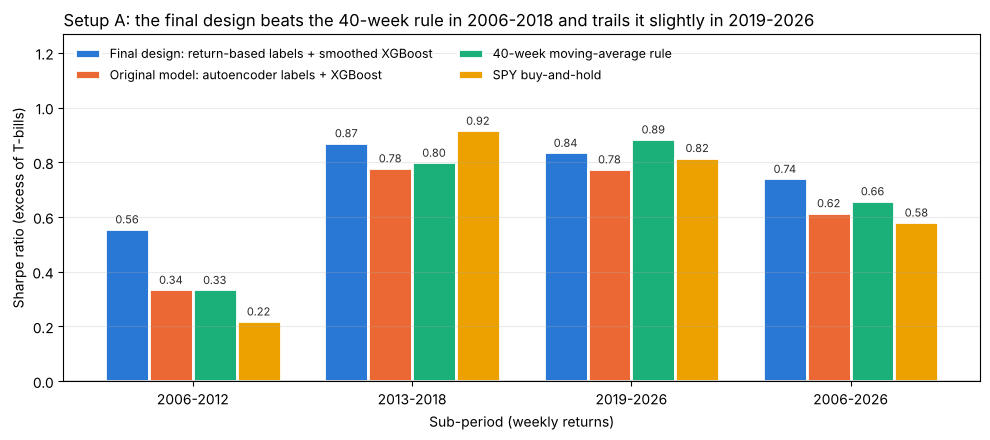

In [ ]:
#  Figure: Sharpe ratio by sub-period, setup A (final design vs the original model, the rule and SPY) 
show = {"Return-based: smoothed XGBoost": ("Final design: return-based labels + smoothed XGBoost", "#2a78d6"),
        "Autoencoder: XGBoost": ("Original model: autoencoder labels + XGBoost", "#eb6834"),
        "40-week rule": ("40-week moving-average rule", "#1baf7a"),
        "SPY buy-and-hold": ("SPY buy-and-hold", "#eda100")}
per = {"2006-2012": ("2006", "2012"), "2013-2018": ("2013", "2018"), "2019-2026": ("2019", "2026"), "2006-2026": ("2006", "2026")}
rets = RESULTS["A: sector ETFs / TLT+GLD"]["rets"]
sr = pd.DataFrame({p: {k: (lambda e: e.mean() / e.std() * np.sqrt(52))(excess(rets[k].loc[a:b])) for k in show}
                   for p, (a, b) in per.items()})
fig, ax = plt.subplots(figsize=(10, 4.5)); w = 0.2
for j, (k, (lab, col)) in enumerate(show.items()):
    xs = np.arange(len(per)) + (j - 1.5) * w
    bars = ax.bar(xs, sr.loc[k], width=w, color=col, edgecolor="white", linewidth=2, label=lab)
    for x_, v in zip(xs, sr.loc[k]):
        ax.text(x_, v + 0.02, f"{v:.2f}", ha="center", fontsize=8, color="#2b2b2a")
ax.set_xticks(np.arange(len(per))); ax.set_xticklabels(list(per)); ax.axhline(0, color="#6b6a64", lw=1)
ax.set_ylabel("Sharpe ratio (excess of T-bills)"); ax.set_xlabel("Sub-period (weekly returns)")
ax.set_title("Setup A: the final design beats the 40-week rule in 2006-2018 and trails it slightly in 2019-2026", loc="left")
ax.legend(frameon=False, fontsize=9, ncol=2, loc="upper left"); ax.set_ylim(0, sr.values.max() + 0.35)
ax.grid(axis="y", alpha=0.25); plt.tight_layout()
plt.savefig(f"{OUT}/figures/sharpe_by_subperiod_setupA.png", dpi=120); plt.show()

### 4.2 Where the gains and losses come from (setup A)

Timing gain or loss relative to always holding the aggressive sleeve, % of portfolio, before costs and ignoring
weight drift, as in section 6.17 of the main notebook. Transitions use each labeller's own causal labels.

In [ ]:
def attribution(sname, labeller):
    idx = RESULTS[sname]["idx"]; r = SETUPS[sname]["r"].loc[idx]; sigs = SIGNALS[sname]
    gap = 100 * W_SAT * (r["Defensive sleeve"] - r["Aggressive sleeve"])
    names = [f"{labeller}: oracle", "40-week rule", f"{labeller}: smoothed XGBoost", "Slow/fast blend",
             f"{labeller}: persistence", f"{labeller}: XGBoost"]
    contrib = pd.DataFrame({n: sigs[n].values * gap.values for n in names}, index=idx)
    o = WF[labeller]; nm = {0: "Trending", 1: "Stressed"}
    bucket = o["now"].loc[idx].astype(int).map(nm) + " -> " + o["next"].loc[idx].astype(int).map(nm)
    t = contrib.groupby(bucket).sum().T; t["TOTAL"] = t.sum(axis=1)
    ag = r["Aggressive sleeve"]; lo, hi = ag.quantile(0.1), ag.quantile(0.9)
    tails = pd.DataFrame({"worst 10% weeks": contrib[ag <= lo].sum(), "best 10% weeks": contrib[ag >= hi].sum(),
                          "middle 80%": contrib[(ag > lo) & (ag < hi)].sum()})
    return t, tails, contrib, bucket.value_counts()

for lab in ["Autoencoder", "Return-based"]:
    t, tails, contrib, counts = attribution("A: sector ETFs / TLT+GLD", lab)
    print(f"\n {lab} labels; weeks per transition: {counts.to_dict()} ")
    print(t.round(1).to_string()); print(tails.round(1).to_string())
    t.round(3).to_csv(f"{OUT}/attribution_{lab}.csv")

_, _, contrib_ae, _ = attribution("A: sector ETFs / TLT+GLD", "Autoencoder")
eps = {"GFC crash Oct 2007-Mar 2009": ("2007-10-12", "2009-03-06"), "Rebound Mar-Dec 2009": ("2009-03-13", "2009-12-31"),
       "Euro crisis Jul-Oct 2011": ("2011-07-01", "2011-10-28"), "Aug 2015-Feb 2016": ("2015-08-14", "2016-02-12"),
       "Q4 2018": ("2018-10-01", "2018-12-28"), "COVID crash Feb-Mar 2020": ("2020-02-14", "2020-03-27"),
       "COVID rebound Apr-Aug 2020": ("2020-04-03", "2020-08-28"), "2022 bear Jan-Oct": ("2022-01-01", "2022-10-14"),
       "Tariff shock Feb-Apr 2025": ("2025-02-21", "2025-04-11"), "Rebound Apr-Jul 2025": ("2025-04-18", "2025-07-25")}
ep = pd.DataFrame({e: contrib_ae.loc[a:b].sum() for e, (a, b) in eps.items()}).T
ep.loc["All other weeks"] = contrib_ae.sum() - ep.sum()
print("\nTiming gain or loss by episode (setup A, autoencoder labels):")
print(ep.round(1).to_string()); ep.round(3).to_csv(f"{OUT}/attribution_episodes.csv")


--- Autoencoder labels; weeks per transition: {'Trending -> Trending': 871, 'Stressed -> Stressed': 120, 'Trending -> Stressed': 45, 'Stressed -> Trending': 45} ---
                               Stressed -> Stressed  Stressed -> Trending  Trending -> Stressed  Trending -> Trending  TOTAL
Autoencoder: oracle                            42.8                   0.0                 103.6                   0.0  146.4
40-week rule                                   36.8                 -53.6                  35.1                 -40.0  -21.8
Autoencoder: smoothed XGBoost                  39.8                 -65.4                  37.8                 -30.5  -18.4
Slow/fast blend                                38.4                 -55.4                  44.7                 -59.6  -31.8
Autoencoder: persistence                       42.8                 -74.4                   0.0                   0.0  -31.5
Autoencoder: XGBoost                           39.0                 -73.0           

### 4.3 Selection bias: deflated information ratio against the 40-week rule (setup A)

In [11]:
def deflated(r_ex, sr_trials, n_trials):
    """Bailey and Lopez de Prado (2014) deflated Sharpe ratio: P(true ratio > best expected from n unskilled trials)."""
    sr, T_ = r_ex.mean() / r_ex.std(), len(r_ex); g3, g4 = skew(r_ex), kurtosis(r_ex, fisher=False); e = 0.5772156649
    sr0 = np.sqrt(np.var(sr_trials, ddof=1)) * ((1 - e) * norm.ppf(1 - 1 / n_trials) + e * norm.ppf(1 - 1 / (n_trials * np.e)))
    return norm.cdf((sr - sr0) * np.sqrt(T_ - 1) / np.sqrt(1 - g3 * sr + (g4 - 1) / 4 * sr ** 2)), sr0 * np.sqrt(52)
rets = RESULTS["A: sector ETFs / TLT+GLD"]["rets"]; rule = rets["40-week rule"]
trials = [k for k in rets if any(s in k for s in ["XGBoost", "persistence", "Slow/fast"])]
ir = pd.Series({k: (rets[k] - rule).mean() / (rets[k] - rule).std() for k in trials})
print("Annualised information ratio vs the 40-week rule (setup A):")
print((ir * np.sqrt(52)).sort_values(ascending=False).round(3).to_string())
best = ir.idxmax()
for n_ in (len(trials), len(trials) + 36):
    p_, ir0 = deflated(rets[best] - rule, ir.values, n_)
    print(f"Best: {best}; trials {n_}: IR {ir[best]*np.sqrt(52):+.3f}, expected max IR under no skill {ir0:.3f}, "
          f"probability the true IR beats the rule {p_:.3f}")

Annualised information ratio vs the 40-week rule (setup A):
Return-based: smoothed XGBoost    0.188
Autoencoder: smoothed XGBoost     0.065
k-means: persistence              0.051
k-means: smoothed XGBoost        -0.033
Autoencoder: persistence         -0.105
k-means: XGBoost                 -0.164
Slow/fast blend                  -0.179
Return-based: persistence        -0.193
Return-based: XGBoost            -0.210
Autoencoder: XGBoost             -0.243
Best: Return-based: smoothed XGBoost; trials 10: IR +0.188, expected max IR under no skill 0.226, probability the true IR beats the rule 0.431
Best: Return-based: smoothed XGBoost; trials 46: IR +0.188, expected max IR under no skill 0.323, probability the true IR beats the rule 0.271


### 4.4 Figure: growth of $1 and drawdown, setup A

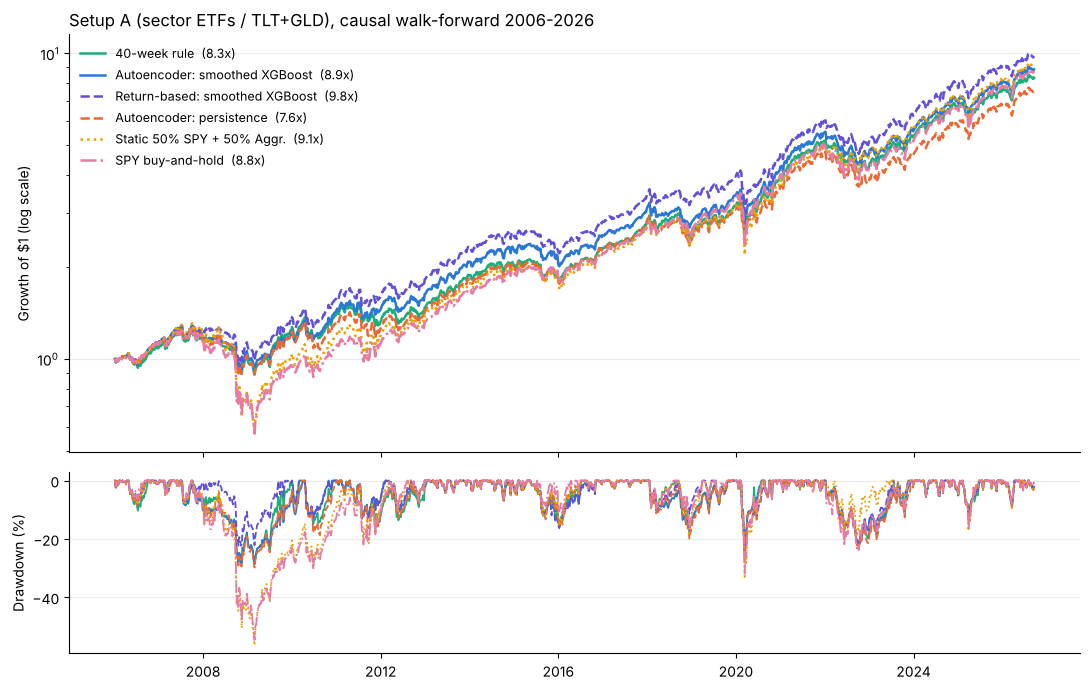

In [12]:
PAL = {"40-week rule": "#1baf7a", "Autoencoder: smoothed XGBoost": "#2a78d6", "Return-based: smoothed XGBoost": "#6250d6",
       "Autoencoder: persistence": "#eb6834", "Static 50% SPY + 50% Aggr.": "#eda100", "SPY buy-and-hold": "#e87ba4"}
STY = {"40-week rule": "-", "Autoencoder: smoothed XGBoost": "-", "Return-based: smoothed XGBoost": "--",
       "Autoencoder: persistence": "--", "Static 50% SPY + 50% Aggr.": ":", "SPY buy-and-hold": "-."}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1.3]})
idx = RESULTS["A: sector ETFs / TLT+GLD"]["idx"]
for n_, col in PAL.items():
    eq = (1 + rets[n_]).cumprod()
    a1.plot(eq.index, eq, color=col, lw=1.8, ls=STY[n_], label=f"{n_}  ({eq.iloc[-1]:.1f}x)")
    a2.plot(eq.index, 100 * (eq / eq.cummax() - 1), color=col, lw=1.3, ls=STY[n_])
a1.set_yscale("log"); a1.set_ylabel("Growth of $1 (log scale)"); a1.grid(axis="y", alpha=0.25)
a1.legend(loc="upper left", frameon=False, fontsize=9)
a1.set_title(f"Setup A (sector ETFs / TLT+GLD), causal walk-forward {idx.min().year}-{idx.max().year}", loc="left")
a2.set_ylabel("Drawdown (%)"); a2.grid(axis="y", alpha=0.25)
plt.tight_layout(); plt.savefig(f"{OUT}/figures/growth_drawdown_setupA.png", dpi=120); plt.show()

## 5 Exploratory trial: smoothed XGBoost for entry, fast trend for exit

**Why.** Across 2006-2026 every strategy loses most of its timing value in the weeks when stress ends: models
and rules alike exit too late. A diagnostic on currently Stressed weeks showed that when SPY's 4-week return has
turned positive, the aggressive sleeve beat the defensive one in about 65% of the following weeks, by about 0.9%
a week on average, while a 1-week signal carried no information.
**What.** Entry is decided by smoothed XGBoost: in the first week it signals Stressed, the satellite moves to the
defensive sleeve. Exit is decided by a fast trend signal: in later weeks of a Stressed signal, the satellite stays
defensive only while SPY's 4-week return is negative (the fast signal of the slow/fast blend, so no new
parameter); otherwise it returns to the aggressive sleeve, and it goes defensive again if the 4-week return turns
negative while the forecast still says Stressed. **How.** Same setups, simulator and tests. This design was
formed after seeing the full sample, so it is reported as an exploratory trial: no untouched holdout remains, and
it is judged on consistency across setups and sub-periods and on the deflated information ratio, not on its
headline Sharpe ratio.

In [13]:
def fast_exit(sm, idx):
    """sm: 0/1 smoothed-XGBoost signal. First week of a Stressed signal: defensive. Later weeks: defensive only
    while SPY's 4-week return is negative."""
    down4 = (X.loc[idx, "ret_4w"] < 0).astype(float).values
    prev = sm.shift(1).fillna(0).values
    return pd.Series(sm.values * np.where(prev == 0, 1.0, down4), index=idx)

HYB = {}
for sname, cfg in SETUPS.items():
    idx, r = RESULTS[sname]["idx"], cfg["r"]; sigs, rets = SIGNALS[sname], RESULTS[sname]["rets"]
    rows = {}
    for lab in ["Autoencoder", "Return-based"]:
        parent = f"{lab}: smoothed XGBoost"; name = f"{lab}: smoothed XGBoost + fast exit"
        sigs[name] = fast_exit(sigs[parent], idx)
        ret, to, _ = run(idx, r, signal=sigs[name]); rets[name] = ret
        o = WF[lab]; now = o["now"].loc[idx].astype(int); nxt = o["next"].loc[idx].astype(int)
        for n_ in [parent, name]:
            s = sigs[n_]
            row = {**metrics(rets[n_]), "Switches": int((s.diff().abs() > 0).sum()), "% defensive": s.mean(),
                   "Entries caught": f"{int(((now == 0) & (nxt == 1) & (s == 1)).sum())}/{int(((now == 0) & (nxt == 1)).sum())}",
                   "Exits caught": f"{int(((now == 1) & (nxt == 0) & (s == 0)).sum())}/{int(((now == 1) & (nxt == 0)).sum())}"}
            refs = ["40-week rule"] + ([parent] if n_ == name else [])
            for ref in refs:
                diff = rets[n_] - rets[ref]; lo, hi = block_boot_ci(diff)
                d_sr, p = lw_sharpe_test(excess(rets[n_]), excess(rets[ref]))
                tag = "rule" if ref == "40-week rule" else "parent"
                row.update({f"vs {tag}: diff": diff.mean() * 52, f"vs {tag}: 95% CI": f"[{lo:+.3f}, {hi:+.3f}]",
                            f"vs {tag}: LW p": p})
            rows[n_] = row
    rows["40-week rule"] = {**metrics(rets["40-week rule"]), "Switches": int((sigs["40-week rule"].diff().abs() > 0).sum()),
                            "% defensive": sigs["40-week rule"].mean()}
    tbl = pd.DataFrame(rows).T
    HYB[sname] = tbl
    print(f"\n=== {sname} ({idx.min().year}-{idx.max().year}) ===")
    disp = tbl.drop(columns=[c for c in tbl.columns if "CI" in c])
    num = [c for c in disp.columns if "caught" not in c]; disp[num] = disp[num].apply(pd.to_numeric)
    print(disp.round(3).fillna("").to_string())
    print(tbl[[c for c in tbl.columns if "CI" in c]].fillna("").to_string())
    tbl.to_csv(f"{OUT}/fast_exit_{sname[0]}.csv")


=== A: sector ETFs / TLT+GLD (2006-2026) ===
                                            Ann. return  Ann. vol  Sharpe (excess)  Max drawdown  Switches  % defensive Entries caught Exits caught vs rule: diff vs rule: LW p vs parent: diff vs parent: LW p
Autoencoder: smoothed XGBoost                     0.111     0.141            0.696        -0.287        32        0.241          22/45        10/45         0.002         0.482                                
Autoencoder: smoothed XGBoost + fast exit         0.117     0.154            0.687        -0.403        68        0.137          13/45        19/45          0.01         0.658           0.008           0.895
Return-based: smoothed XGBoost                    0.116     0.138            0.741        -0.272        38        0.278          30/58        15/58         0.007         0.137                                
Return-based: smoothed XGBoost + fast exit        0.123     0.150            0.738        -0.365        78        0.160   


=== B: S&P 100 stocks / TLT+GLD (2006-2026) ===
                                            Ann. return  Ann. vol  Sharpe (excess)  Max drawdown  Switches  % defensive Entries caught Exits caught vs rule: diff vs rule: LW p vs parent: diff vs parent: LW p
Autoencoder: smoothed XGBoost                     0.151     0.166            0.828        -0.299        32        0.225          19/45        12/45        -0.005         0.785                                
Autoencoder: smoothed XGBoost + fast exit         0.169     0.189            0.828        -0.463        66        0.126          10/45        21/45         0.014         0.821           0.019             1.0
Return-based: smoothed XGBoost                    0.154     0.159            0.874        -0.237        30        0.248          26/58        19/58        -0.003         0.725                                
Return-based: smoothed XGBoost + fast exit        0.178     0.184            0.891        -0.418        68        0.141


=== C: sector ETFs / T-bills (2001-2026) ===
                                            Ann. return  Ann. vol  Sharpe (excess)  Max drawdown  Switches  % defensive Entries caught Exits caught vs rule: diff vs rule: LW p vs parent: diff vs parent: LW p
Autoencoder: smoothed XGBoost                     0.091     0.140            0.564        -0.371        43        0.210          14/58        27/59         0.004         0.729                                
Autoencoder: smoothed XGBoost + fast exit         0.097     0.152            0.568        -0.430        81        0.131           5/58        37/59         0.012          0.74           0.007           0.935
Return-based: smoothed XGBoost                    0.096     0.138            0.605        -0.350        37        0.234          15/69        39/68         0.009         0.087                                
Return-based: smoothed XGBoost + fast exit        0.104     0.150            0.617        -0.421        81        0.141   

In [ ]:
#  Consistency: Sharpe (excess) by sub-period, and where the change comes from (setup A) 
KEY2 = ["Return-based: smoothed XGBoost + fast exit", "Return-based: smoothed XGBoost",
        "Autoencoder: smoothed XGBoost + fast exit", "Autoencoder: smoothed XGBoost", "40-week rule", "SPY buy-and-hold"]
def sub2(sname, periods):
    rets = RESULTS[sname]["rets"]
    return pd.DataFrame({p: {k: (lambda e: e.mean() / e.std() * np.sqrt(52))(excess(rets[k].loc[a:b])) for k in KEY2}
                         for p, (a, b) in periods.items()}).round(2)
print("Setup A:"); print(sub2("A: sector ETFs / TLT+GLD", pA).to_string())
print("\nSetup B:"); print(sub2("B: S&P 100 stocks / TLT+GLD", pA).to_string())
print("\nSetup C:"); print(sub2("C: sector ETFs / T-bills", {"2001-2005": ("2001", "2005"), "2006-2012": ("2006", "2012"),
      "2013-2018": ("2013", "2018"), "2019-2026": ("2019", "2026"), "All": ("2001", "2026")}).to_string())

sname = "A: sector ETFs / TLT+GLD"; idx = RESULTS[sname]["idx"]; r = SETUPS[sname]["r"].loc[idx]; sigs = SIGNALS[sname]
gap = 100 * W_SAT * (r["Defensive sleeve"] - r["Aggressive sleeve"]); nm = {0: "Trending", 1: "Stressed"}
for lab in ["Return-based", "Autoencoder"]:
    names = ["40-week rule", f"{lab}: smoothed XGBoost", f"{lab}: smoothed XGBoost + fast exit"]
    contrib = pd.DataFrame({n: sigs[n].values * gap.values for n in names}, index=idx)
    o = WF[lab]; bucket = o["now"].loc[idx].astype(int).map(nm) + " -> " + o["next"].loc[idx].astype(int).map(nm)
    t = contrib.groupby(bucket).sum().T; t["TOTAL"] = t.sum(axis=1)
    ep = pd.DataFrame({e: contrib.loc[a:b].sum() for e, (a, b) in eps.items()}).T
    print(f"\n Setup A, {lab} labels: timing gain/loss by transition (% of portfolio) "); print(t.round(1).to_string())
    print("by episode:"); print(ep.round(1).to_string())

# Deflated information ratio vs the rule, setup A, with the two new trials added
rets = RESULTS[sname]["rets"]; rule = rets["40-week rule"]
trials = [k for k in rets if any(s in k for s in ["XGBoost", "persistence", "Slow/fast"])]
ir = pd.Series({k: (rets[k] - rule).mean() / (rets[k] - rule).std() for k in trials})
print("\nAnnualised information ratio vs the 40-week rule (setup A), top 5:")
print((ir * np.sqrt(52)).sort_values(ascending=False).head(5).round(3).to_string())
best = ir.idxmax()
for n_ in (len(trials), len(trials) + 36):
    p_, ir0 = deflated(rets[best] - rule, ir.values, n_)
    print(f"Best: {best}; trials {n_}: IR {ir[best]*np.sqrt(52):+.3f}, expected max under no skill {ir0:.3f}, "
          f"probability the true IR beats the rule {p_:.3f}")

Setup A:
                                            2006-2012  2013-2018  2019-2026   All
Return-based: smoothed XGBoost + fast exit       0.40       0.96       0.95  0.74
Return-based: smoothed XGBoost                   0.56       0.87       0.84  0.74
Autoencoder: smoothed XGBoost + fast exit        0.34       0.83       0.94  0.69
Autoencoder: smoothed XGBoost                    0.44       0.76       0.89  0.70
40-week rule                                     0.33       0.80       0.89  0.66
SPY buy-and-hold                                 0.22       0.92       0.82  0.58

Setup B:
                                            2006-2012  2013-2018  2019-2026   All
Return-based: smoothed XGBoost + fast exit       0.53       1.05       1.20  0.89
Return-based: smoothed XGBoost                   0.64       0.98       1.01  0.87
Autoencoder: smoothed XGBoost + fast exit        0.46       0.95       1.16  0.83
Autoencoder: smoothed XGBoost                    0.55       0.90       1.02  0.

                                            2001-2005  2006-2012  2013-2018  2019-2026   All
Return-based: smoothed XGBoost + fast exit       0.33       0.32       0.81       0.98  0.62
Return-based: smoothed XGBoost                   0.35       0.35       0.75       0.91  0.61
Autoencoder: smoothed XGBoost + fast exit        0.26       0.28       0.74       0.93  0.57
Autoencoder: smoothed XGBoost                    0.34       0.26       0.69       0.91  0.56
40-week rule                                     0.16       0.28       0.72       0.91  0.55
SPY buy-and-hold                                 0.19       0.22       0.92       0.82  0.51

--- Setup A, Return-based labels: timing gain/loss by transition (% of portfolio) ---
                                            Stressed -> Stressed  Stressed -> Trending  Trending -> Stressed  Trending -> Trending  TOTAL
40-week rule                                                54.1                 -75.2                  26.8                

                             40-week rule  Return-based: smoothed XGBoost  Return-based: smoothed XGBoost + fast exit
GFC crash Oct 2007-Mar 2009          33.1                            40.2                                        22.0
Rebound Mar-Dec 2009                -15.6                           -22.0                                        -7.4
Euro crisis Jul-Oct 2011             -0.4                             2.6                                         2.6
Aug 2015-Feb 2016                     3.1                             0.8                                         7.5
Q4 2018                               0.0                             7.8                                         2.9
COVID crash Feb-Mar 2020             13.2                             9.1                                         9.1
COVID rebound Apr-Aug 2020          -10.9                           -14.5                                       -11.3
2022 bear Jan-Oct                   -10.6               

## 6 Model comparison on equal terms: logistic regression, LSTM and XGBoost

**Why.** XGBoost was chosen for the walk-forward after a single train/validation/test split, where it had the
best AUC but logistic regression had a slightly higher (not significant) test-period Sharpe ratio, and the LSTM,
the only model that reads the weeks as a sequence, was never tested out of sample year by year. A reviewer can
fairly ask whether the choice of model drives the result.
**What.** Logistic regression (unweighted, standardised inputs) and the LSTM (last 8 weeks as a sequence, 16
hidden units, the settings of the main study) are run through exactly the same causal walk-forward as XGBoost:
the same vintage labels, inputs, yearly refits, break-even thresholds and 2-week smoothing, for the autoencoder
and the return-based labels, in all three setups. The LSTM early-stops on a random 15% of the training sequences.
**How.** Forecast skill 2000-2026, portfolio results per setup, sub-periods, and the deflated information ratio
with these eight variants added to the trial count.

In [15]:
from sklearn.linear_model import LogisticRegression

class SeqNet(nn.Module):
    def __init__(self, n_in, hidden=16):
        super().__init__(); self.lstm = nn.LSTM(n_in, hidden, batch_first=True); self.head = nn.Linear(hidden, 1)
    def forward(self, x):
        out, _ = self.lstm(x); return self.head(out[:, -1]).squeeze(-1)

def fit_predict(model, D, tr, te, L=8, seed=SEED):
    """Fit logistic regression or the LSTM on the training weeks tr of one vintage and forecast the weeks te."""
    y_tr = D.loc[tr, "next_regime"].astype(int).values
    sc = StandardScaler().fit(D.loc[tr, STATE_COLS])
    if model == "Logistic":
        clf = LogisticRegression(C=1.0, max_iter=2000).fit(sc.transform(D.loc[tr, STATE_COLS]), y_tr)
        return clf.predict_proba(sc.transform(D.loc[te, STATE_COLS]))[:, 1]
    # LSTM: each week is the sequence of its last L weekly input vectors (all from before or at that week)
    A = sc.transform(D[STATE_COLS]).astype(np.float32); pos = {d: i for i, d in enumerate(D.index)}
    def seqs(idx):
        ii = np.array([pos[d] for d in idx]); ii = ii[ii >= L - 1]
        return torch.tensor(np.stack([A[i - L + 1:i + 1] for i in ii])), ii
    Xtr, itr = seqs(tr); ytr = torch.tensor(D["next_regime"].values[itr].astype(np.float32))
    Xte, ite = seqs(te)
    torch.manual_seed(seed); np.random.seed(seed)
    hold = np.random.default_rng(seed).random(len(ytr)) < 0.15
    net = SeqNet(len(STATE_COLS)); opt = torch.optim.Adam(net.parameters(), lr=1e-3, weight_decay=1e-4)
    bce = nn.BCEWithLogitsLoss(); best, state, wait = np.inf, None, 0
    for ep in range(600):
        net.train(); opt.zero_grad(); bce(net(Xtr[~hold]), ytr[~hold]).backward(); opt.step()
        net.eval()
        with torch.no_grad():
            v = bce(net(Xtr[hold]), ytr[hold]).item()
        if v < best - 1e-4:
            best, wait, state = v, 0, {k: w.clone() for k, w in net.state_dict().items()}
        else:
            wait += 1
            if wait >= 40:
                break
    net.load_state_dict(state); net.eval()
    with torch.no_grad():
        p = torch.sigmoid(net(Xte)).numpy()
    out = np.full(len(te), np.nan); out[np.searchsorted(te, D.index[ite])] = p
    return out

MODELS = ["Logistic", "LSTM"]
for lab in ["Autoencoder", "Return-based"]:
    o = WF[lab]
    for m in MODELS:
        prob = pd.Series(np.nan, index=X.index)
        for y in YEARS:
            D, tr, te = o["D"][y]
            prob.loc[te] = fit_predict(m, D, tr, te)
        prob = prob.loc[o["prob"].index]
        o[f"prob_{m}"] = prob; o[f"smooth_{m}"] = prob.ewm(halflife=2, adjust=False).mean()
    o["prob_XGBoost"], o["smooth_XGBoost"] = o["prob"], o["smooth"]

rows = []
for lab in ["Autoencoder", "Return-based"]:
    o = WF[lab]; now_, nxt_ = o["now"].astype(int), o["next"].astype(int); tw, sw = now_ == 0, now_ == 1
    for m in ["XGBoost"] + MODELS:
        for kind in ["prob", "smooth"]:
            p = o[f"{kind}_{m}"]
            rows.append({"labels": lab, "model": m + (" (smoothed)" if kind == "smooth" else ""),
                         "AUC": roc_auc_score(nxt_, p), "Brier": brier_score_loss(nxt_, p),
                         "AUC entry (now Trending)": roc_auc_score(nxt_[tw], p[tw]),
                         "AUC exit (now Stressed)": roc_auc_score(nxt_[sw], p[sw])})
    rows.append({"labels": lab, "model": "Persistence", "AUC": roc_auc_score(nxt_, now_),
                 "Brier": brier_score_loss(nxt_, now_), "AUC entry (now Trending)": 0.5, "AUC exit (now Stressed)": 0.5})
skill_m = pd.DataFrame(rows).set_index(["labels", "model"]).round(3)
print("Forecast skill 2000-2026, same causal walk-forward for every model:")
print(skill_m.to_string()); skill_m.to_csv(f"{OUT}/model_comparison_skill.csv")

Forecast skill 2000-2026, same causal walk-forward for every model:
                                    AUC  Brier  AUC entry (now Trending)  AUC exit (now Stressed)
labels       model                                                                               
Autoencoder  XGBoost              0.947  0.068                     0.837                    0.844
             XGBoost (smoothed)   0.934  0.076                     0.810                    0.808
             Logistic             0.953  0.062                     0.852                    0.868
             Logistic (smoothed)  0.935  0.075                     0.815                    0.812
             LSTM                 0.941  0.072                     0.833                    0.788
             LSTM (smoothed)      0.923  0.082                     0.794                    0.782
             Persistence          0.869  0.091                     0.500                    0.500
Return-based XGBoost              0.944  0.081    

In [ ]:
#  Portfolio results for every model, raw and smoothed, in each setup 
CMP = {}
for sname, cfg in SETUPS.items():
    idx, r = RESULTS[sname]["idx"], cfg["r"]; sigs, rets = SIGNALS[sname], RESULTS[sname]["rets"]
    rows = {}
    for lab in ["Autoencoder", "Return-based"]:
        o = WF[lab]; thr = thresholds(o, cfg, idx)
        for m in ["XGBoost"] + MODELS:
            for kind in ["prob", "smooth"]:
                name = f"{lab}: {m}" + (" (smoothed)" if kind == "smooth" else "")
                if name not in sigs:
                    sigs[name] = (o[f"{kind}_{m}"].loc[idx] >= thr).astype(float)
                    rets[name] = run(idx, r, signal=sigs[name])[0]
                diff = rets[name] - rets["40-week rule"]; lo, hi = block_boot_ci(diff)
                d_sr, p = lw_sharpe_test(excess(rets[name]), excess(rets["40-week rule"]))
                rows[name] = {**metrics(rets[name]), "Switches": int((sigs[name].diff().abs() > 0).sum()),
                              "Diff vs rule": diff.mean() * 52, "95% CI": f"[{lo:+.3f}, {hi:+.3f}]", "LW p": p}
    for ref in ["40-week rule", "SPY buy-and-hold"]:
        rows[ref] = metrics(rets[ref])
    tbl = pd.DataFrame(rows).T
    num = [c for c in tbl.columns if c != "95% CI"]; tbl[num] = tbl[num].apply(pd.to_numeric)
    CMP[sname] = tbl
    print(f"\n=== {sname} ({idx.min().year}-{idx.max().year}) ===")
    print(tbl.round(3).fillna("").to_string())
    tbl.round(4).to_csv(f"{OUT}/model_comparison_{sname[0]}.csv")

print("\nSharpe ratio (excess) by setup, smoothed versions:")
print(pd.DataFrame({s[:1]: CMP[s]["Sharpe (excess)"] for s in CMP}).loc[
      [f"{l}: {m}" + suf for l in ["Return-based", "Autoencoder"] for m in ["XGBoost", "Logistic", "LSTM"] for suf in ["", " (smoothed)"]]
      + ["40-week rule", "SPY buy-and-hold"]].round(2).to_string())


=== A: sector ETFs / TLT+GLD (2006-2026) ===
                                   Ann. return  Ann. vol  Sharpe (excess)  Max drawdown Switches Diff vs rule            95% CI   LW p
Autoencoder: XGBoost                     0.099     0.142            0.616        -0.297     70.0       -0.008  [-0.022, +0.006]  0.374
Autoencoder: XGBoost (smoothed)          0.111     0.141            0.696        -0.287     32.0        0.002  [-0.012, +0.017]  0.482
Autoencoder: Logistic                    0.106     0.143            0.656        -0.301     70.0       -0.002  [-0.014, +0.011]  0.936
Autoencoder: Logistic (smoothed)         0.112     0.140            0.706        -0.273     30.0        0.003  [-0.012, +0.019]  0.382
Autoencoder: LSTM                        0.111     0.143            0.685        -0.319     48.0        0.003  [-0.013, +0.018]  0.606
Autoencoder: LSTM (smoothed)             0.112     0.142            0.698        -0.270     24.0        0.004  [-0.013, +0.020]  0.477
Return-ba


=== B: S&P 100 stocks / TLT+GLD (2006-2026) ===
                                   Ann. return  Ann. vol  Sharpe (excess)  Max drawdown Switches Diff vs rule            95% CI   LW p
Autoencoder: XGBoost                     0.146     0.167            0.799        -0.310     70.0       -0.009  [-0.033, +0.014]   0.47
Autoencoder: XGBoost (smoothed)          0.151     0.166            0.828        -0.299     32.0       -0.005  [-0.031, +0.020]  0.785
Autoencoder: Logistic                    0.151     0.169            0.817        -0.333     76.0       -0.005  [-0.027, +0.016]  0.576
Autoencoder: Logistic (smoothed)         0.148     0.164            0.821        -0.307     32.0       -0.008  [-0.034, +0.016]  0.717
Autoencoder: LSTM                        0.157     0.170            0.846        -0.333     56.0        0.001  [-0.026, +0.026]  0.963
Autoencoder: LSTM (smoothed)             0.156     0.166            0.853        -0.271     26.0       -0.001  [-0.029, +0.024]  0.967
Return


=== C: sector ETFs / T-bills (2001-2026) ===
                                   Ann. return  Ann. vol  Sharpe (excess)  Max drawdown Switches Diff vs rule            95% CI   LW p
Autoencoder: XGBoost                     0.083     0.142            0.505        -0.377     89.0       -0.003  [-0.015, +0.009]  0.249
Autoencoder: XGBoost (smoothed)          0.091     0.140            0.564        -0.371     43.0        0.004  [-0.008, +0.016]  0.729
Autoencoder: Logistic                    0.081     0.141            0.498        -0.370    105.0       -0.004  [-0.016, +0.007]   0.18
Autoencoder: Logistic (smoothed)         0.091     0.140            0.566        -0.383     33.0        0.005  [-0.008, +0.017]  0.715
Autoencoder: LSTM                        0.091     0.141            0.566        -0.355     71.0        0.005  [-0.007, +0.017]  0.687
Autoencoder: LSTM (smoothed)             0.093     0.141            0.578        -0.353     31.0        0.007  [-0.006, +0.019]  0.539
Return-ba

In [ ]:
#  Consistency over sub-periods (setup A) and selection bias with every model variant counted 
rets = RESULTS["A: sector ETFs / TLT+GLD"]["rets"]
keys = [f"Return-based: {m} (smoothed)" for m in ["XGBoost", "Logistic", "LSTM"]] + \
       [f"Return-based: {m}" for m in ["XGBoost", "Logistic", "LSTM"]] + ["40-week rule"]
print("Sharpe (excess) by sub-period, setup A:")
print(pd.DataFrame({p: {k: (lambda e: e.mean() / e.std() * np.sqrt(52))(excess(rets[k].loc[a:b])) for k in keys}
                    for p, (a, b) in pA.items()}).round(2).to_string())
rule = rets["40-week rule"]
cand = [k for k in rets if any(s in k for s in ["XGBoost", "Logistic", "LSTM", "persistence", "Slow/fast"])]
trials = []
for k in cand:                                   # the same strategy listed under two names counts once
    if not any(np.allclose(rets[k].values, rets[t].values) for t in trials):
        trials.append(k)
ir = pd.Series({k: (rets[k] - rule).mean() / (rets[k] - rule).std() for k in trials})
print(f"\nTrials on setup A (distinct strategies): {len(trials)}. Annualised information ratio vs the 40-week rule, top 8:")
print((ir * np.sqrt(52)).sort_values(ascending=False).head(8).round(3).to_string())
best = ir.idxmax()
for n_ in (len(trials), len(trials) + 36):
    p_, ir0 = deflated(rets[best] - rule, ir.values, n_)
    print(f"Best: {best}; trials {n_}: IR {ir[best]*np.sqrt(52):+.3f}, expected max under no skill {ir0:.3f}, "
          f"probability the true IR beats the rule {p_:.3f}")

Sharpe (excess) by sub-period, setup A:
                                   2006-2012  2013-2018  2019-2026   All
Return-based: XGBoost (smoothed)        0.56       0.87       0.84  0.74
Return-based: Logistic (smoothed)       0.45       0.77       0.83  0.68
Return-based: LSTM (smoothed)           0.55       0.82       0.85  0.73
Return-based: XGBoost                   0.39       0.77       0.78  0.63
Return-based: Logistic                  0.35       0.71       0.82  0.62
Return-based: LSTM                      0.45       0.72       0.83  0.66
40-week rule                            0.33       0.80       0.89  0.66

Trials on setup A (distinct strategies): 20. Annualised information ratio vs the 40-week rule, top 8:
Return-based: smoothed XGBoost + fast exit    0.335
Autoencoder: smoothed XGBoost + fast exit     0.226
Return-based: smoothed XGBoost                0.188
Return-based: LSTM (smoothed)                 0.144
Autoencoder: Logistic (smoothed)              0.092
Autoencoder: 